In [1]:
import numpy as np
import re
import math
import sys
from collections import defaultdict, Counter
import json
import itertools
import warnings
import statistics
from pathlib import Path
import zipfile
from scipy import interpolate
from matplotlib import pyplot as plt
%matplotlib inline

In [65]:
def notebook_path_on_disk():
    return Path(json.loads(Path(sys.argv[-1]).read_bytes())['jupyter_session'])

modification_data = {
    'short_across_traces': [31, 32, 33, 34, 35, 41, 42, 43, 44, 45],
    'short_within_trace': [26, 27, 28, 29, 30, 46, 47, 48, 49, 50],
    'open': [21, 22, 23, 24, 25, 36, 37, 38, 39, 40],
    'probe_points': [53, 54, 55],
}

baseline_serials = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

def load_multichannel_data(path=None):
    if path is None:
        # Get the data dir independent on where exactly the Jupyter server is running
        path = notebook_path_on_disk().parent.parent / 'data_multi'
        
    data_dict = defaultdict(list)
    data_dict_runs = defaultdict(list)
    for le_zip in path.glob('*.zip'):
        le_zip = zipfile.ZipFile(le_zip)
        for entry in le_zip.infolist():
            if not entry.filename.endswith('.json'):
                continue
            data = json.loads(le_zip.read(entry))
            info = data['info']
            meta, specimen = info['meta'], info['specimen']
            mesh_id = specimen
            _rest, _, serial = specimen.rpartition('-')
            try:
                serial = int(serial)
            except:
                serial = 'none'

            mods = []
            for modification, matching_serials in modification_data.items():
                if serial in matching_serials:
                    mods.append(modification)
            info['mods'] = mods

            if (g := re.search(r'p([.0-9]+)', meta)):
                pitch = str(float(*g.groups()))
            else:
                warnings.warn(f'Unknown pitch for {meta!r}')
                pitch = '?'

            mesh_layout = re.sub(r'-\d{4}', '', specimen)
            
            if (g := re.search(r'side-([ab])-(right|left)', meta)):
                layer, half = g.groups()
                mesh_id = f'M-{specimen}-{pitch}-{layer}-{half}'
                mesh_layout += f'-{layer}-{half}'
            else:
                mesh_id = f'M-{specimen}-{pitch}'
            info['mesh_id'] = mesh_id
            info['mesh_layout'] = mesh_layout
            info['pitch'] = pitch
            info['serial'] = serial if serial != 'none' else 0
            info['baseline'] = (serial in baseline_serials)
            data_dict[mesh_id].append(data)
            data_dict_runs[meta].append(data)
    return data_dict, data_dict_runs

data, data_runs = load_multichannel_data()

/tmp/ipykernel_11577/4002247167.py:44: UserWarning: Unknown pitch for 'cal-open'
  warnings.warn(f'Unknown pitch for {meta!r}')
/tmp/ipykernel_11577/4002247167.py:44: UserWarning: Unknown pitch for 'baseline-5-open'
  warnings.warn(f'Unknown pitch for {meta!r}')


In [3]:
{key: value[0]['info'].get('mods') for key, value in data.items()}

{'M-SP-PITCH-V2-0100-0.3': [],
 'M-SP-PITCH-V2-0097-0.3': [],
 'M-SP-PITCH-V2-0096-0.3': [],
 'M-SP-PITCH-V2-0099-0.3': [],
 'M-SP-PITCH-V2-0098-0.3': [],
 'M-SP-PITCH-V2-0095-0.3': [],
 'M-SP-PITCH-V2-0094-0.3': [],
 'M-SP-PITCH-V2-0093-0.3': [],
 'M-SP-PITCH-V2-0092-0.3': [],
 'M-SP-PITCH-V2-0091-0.3': [],
 'M-SP-PITCH-V2-0090-0.3': [],
 'M-SP-PITCH-V2-0089-0.3': [],
 'M-SP-PITCH-V2-0088-0.3': [],
 'M-SP-PITCH-V2-0087-0.3': [],
 'M-SP-PITCH-V2-0086-0.3': [],
 'M-SP-PITCH-V2-0085-0.3': [],
 'M-SP-PITCH-V2-0084-0.3': [],
 'M-SP-PITCH-V2-0083-0.3': [],
 'M-SP-PITCH-V2-0082-0.3': [],
 'M-SP-PITCH-V2-0081-0.3': [],
 'M-SP-PITCH-V2-0080-0.3': [],
 'M-SP-PITCH-V2-0079-0.3': [],
 'M-SP-PITCH-V2-0078-0.3': [],
 'M-SP-PITCH-V2-0077-0.3': [],
 'M-SP-PITCH-V2-0076-0.3': [],
 'M-SP-PITCH-V2-0075-0.3': [],
 'M-SP-PITCH-V2-0074-0.3': [],
 'M-SP-PITCH-V2-0073-0.3': [],
 'M-SP-PITCH-V2-0072-0.3': [],
 'M-SP-PITCH-V2-0071-0.3': [],
 'M-SP-PITCH-V2-0070-0.3': [],
 'M-SP-PITCH-V2-0069-0.3': [],
 'M-SP-P

In [4]:
Counter([value['info']['meta'] for entries in data.values() for value in entries])

Counter({'Baseline-2-p0.3': 100,
         'Baseline-1-p0.3': 30,
         'Baseline-2-p0.4': 30,
         'probe-interleave-25-07-02-01-p0.4': 28,
         'probe-interleave-25-07-02-01-p0.3': 26,
         'Baseline-1-p0.4': 25,
         'touch-interleave-touch-serial-5-25-07-02-01-p0.3': 23,
         'interleaved-25-07-02-01-p0.3': 20,
         'interleaved-25-07-02-02-p0.3': 20,
         'touch-ground-interleave-touch-serial-5-25-07-02-01-p0.3': 20,
         'hot-mesh-hot-serial-5-25-07-02-01-p0.3': 20,
         'mods-25-07-01-01-p0.3': 16,
         'mods-25-07-01-01-p0.4': 16,
         'baseline-4-p0.4': 15,
         'mods-25-07-01-01-p0.6': 15,
         'mods-25-07-01-01-p1.0': 15,
         'mod-25-07-02-01-p0.3': 12,
         'baseline-repeat-25-07-02-01-p0.3': 11,
         'baseline-repeat-25-07-02-02-p0.3': 10,
         'baseline-4-p0.3': 10,
         'Baseline-2-alt-side-a-right-p0.4': 10,
         'Baseline-1-alt-side-a-right-p0.4': 10,
         'Baseline-2-alt-side-a-left-p0.

In [5]:
for foo in data.values():
    for elem in foo:
        if elem['info']['meta'] == 'mods-25-07-01-01-p0.4':
            print(elem['info'])

{'meta': 'mods-25-07-01-01-p0.4', 'specimen': 'SP-PITCH-V2-0021', 'mcu': '203632423631500f003f0034', 'chip': 'pi3hdx12211', 'timestamp': '2025-07-01T13:51:08.938Z', 'mods': ['open'], 'mesh_id': 'M-SP-PITCH-V2-0021-0.4', 'mesh_layout': 'SP-PITCH-V2', 'pitch': '0.4', 'serial': 21}
{'meta': 'mods-25-07-01-01-p0.4', 'specimen': 'SP-PITCH-V2-0022', 'mcu': '203632423631500f003f0034', 'chip': 'pi3hdx12211', 'timestamp': '2025-07-01T13:51:28.628Z', 'mods': ['open'], 'mesh_id': 'M-SP-PITCH-V2-0022-0.4', 'mesh_layout': 'SP-PITCH-V2', 'pitch': '0.4', 'serial': 22}
{'meta': 'mods-25-07-01-01-p0.4', 'specimen': 'SP-PITCH-V2-0023', 'mcu': '203632423631500f003f0034', 'chip': 'pi3hdx12211', 'timestamp': '2025-07-01T13:51:42.076Z', 'mods': ['open'], 'mesh_id': 'M-SP-PITCH-V2-0023-0.4', 'mesh_layout': 'SP-PITCH-V2', 'pitch': '0.4', 'serial': 23}
{'meta': 'mods-25-07-01-01-p0.4', 'specimen': 'SP-PITCH-V2-0024', 'mcu': '203632423631500f003f0034', 'chip': 'pi3hdx12211', 'timestamp': '2025-07-01T13:52:00.66

In [6]:
[value['info'] for entries in data.values() for value in entries if value['info']['meta'] == 'mods-25-07-01-01-p0.3']

[{'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0035',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:28:35.483Z',
  'mods': ['short_across_traces'],
  'mesh_id': 'M-SP-PITCH-V2-0035-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 35},
 {'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0034',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:28:55.114Z',
  'mods': ['short_across_traces'],
  'mesh_id': 'M-SP-PITCH-V2-0034-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 34},
 {'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PITCH-V2-0033',
  'mcu': '203632423631500f003f0034',
  'chip': 'pi3hdx12211',
  'timestamp': '2025-07-01T13:29:13.962Z',
  'mods': ['short_across_traces'],
  'mesh_id': 'M-SP-PITCH-V2-0033-0.3',
  'mesh_layout': 'SP-PITCH-V2',
  'pitch': '0.3',
  'serial': 33},
 {'meta': 'mods-25-07-01-01-p0.3',
  'specimen': 'SP-PI

In [7]:
def newest_for_mesh(chip='pi3hdx12211'):
    out = {}
    for key, entries in data.items():
        entries = [e for e in entries if e['info']['chip'] == chip]
        out[key] = entries[0]
        for value in entries[1:]:
            if value['info']['timestamp'] > out[key]['info']['timestamp']:
                out[key] = value
    return out

data_newest = newest_for_mesh()
mod_baseline = {pitch: [
                        data_newest[f'M-SP-PITCH-V2-{serial:04d}-{pitch}']
                        for serial in [1,2,3,4,5]]
                for pitch in [0.3, 0.4, 0.6, 1.0]}

mod_modified = {(mod, pitch): [
                        value
                        for value in data_newest.values()
                        if mod in value['info']['mods']
                        and value['info']['pitch'] == str(pitch)]
                for mod, pitch in itertools.product(['open', 'short_within_trace', 'short_across_traces'],
                                                    [0.3, 0.4, 0.6, 1.0])}
one_specimen_baseline = {pitch:
                         [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == f'M-SP-PITCH-V2-0005-{pitch}'][-5:]
                         for pitch in [0.3, 0.4, 0.6, 1.0]}

#{k: [e['info']['timestamp'] for e in v] for k, v in mod_baseline.items()}
#{k: [e['info']['meta'] for e in v] for k, v in mod_modified.items()}
{k: [e['info']['timestamp'] for e in v] for k, v in one_specimen_baseline.items()}

{0.3: ['2025-07-02T15:01:23.851Z',
  '2025-07-02T15:01:37.534Z',
  '2025-07-02T15:01:44.213Z',
  '2025-07-02T15:01:50.886Z',
  '2025-07-01T13:00:21.356Z'],
 0.4: ['2025-06-27T14:48:51.116Z',
  '2025-06-27T14:50:14.712Z',
  '2025-06-27T14:51:49.996Z',
  '2025-06-27T14:53:07.147Z',
  '2025-07-01T13:03:55.562Z'],
 0.6: ['2025-07-01T13:08:49.451Z', '2025-07-01T13:19:55.971Z'],
 1.0: ['2025-07-01T13:20:32.218Z']}

In [8]:
len([val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:])
len(list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values()))

5

Baseline threshold set at 0.999976
Within class: 1±9.66e-06 max: 1
Cross class: 1±3.37e-05 max: 1
Baseline false negative probability: 0.055268299027
Baseline false positive probability: 0.323891986799


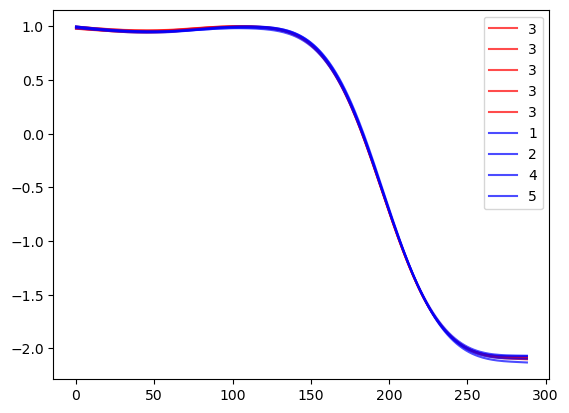

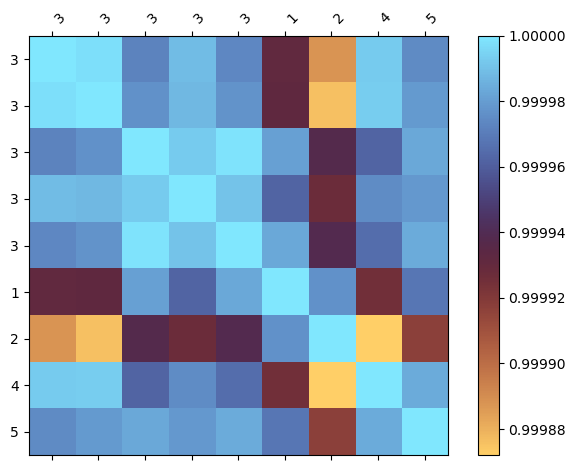

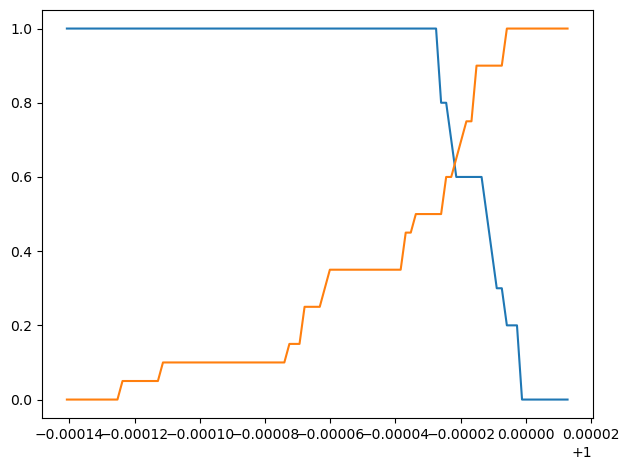

In [9]:
roi_map = {
    'tdp0604': (155, 445),
    'pi3hdx12211': (160, 450),
}
foo = list(roi_map.values())[0]
roi_n = foo[1] - foo[0]

def plot_covar(group_a, group_b, select_trace='open_fwd', select_channel='adc1', smooth=None, plot_cdf=False):
    group_a = sorted(group_a, key=lambda entry: entry['info']['serial'])
    group_b = sorted(group_b, key=lambda entry: entry['info']['serial'])
    all_traces = group_a + group_b
        
    d = np.zeros((len(all_traces), roi_n))
    labels = []
    for i, trace in enumerate(all_traces):
        trace_data = trace['data'][select_trace][select_channel]
        start, end = roi_map[trace['info']['chip']]
        trace_data = trace_data[start:end]

        if smooth is not None:
            t = np.linspace(0, 1, len(trace_data))
            spl = interpolate.make_smoothing_spline(t, trace_data, lam=smooth)
            trace_data = spl(t)
        
        d[i] = trace_data
        labels.append(str(trace['info']['serial']))
        
    
    # Normalize each curve such that its mean is at 0 and its min is at -1
    deltas = d[:,1:]
    deltas -= np.repeat(deltas.mean(axis=1)[:,np.newaxis], roi_n-1, axis=1)
    deltas /= np.repeat(deltas.max(axis=1)[:,np.newaxis], roi_n-1, axis=1)
    
    # Align all curves such that the trace starts where the trace crosses 0.5
    #roi_refined = round(np.mean(roi_n - 1 - np.argmax(deltas[:,::-1] > 0.5, axis=1))), roi_n
    #deltas = deltas[:,roi_refined[0]:roi_refined[1]]
    
    corr = np.corrcoef(deltas)
    
    fig, ax = plt.subplots()
    for i, (x, lab) in enumerate(zip(deltas, labels)):
        ax.plot(x, label=lab, color=('red' if i<len(group_a) else 'blue'), alpha=0.7)
    ax.legend()
    
    within_class = corr[:4, :4][np.triu_indices(4)]
    cross_class = corr[4:, :4].flatten()
    
    cdf = lambda x, mu, sigma: 1/2 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))
    threshold = (np.mean(within_class) + np.mean(cross_class)) / 2
    print(f'Baseline threshold set at {threshold:.6f}')
    
    for name, data in [('Within', within_class), ('Cross', cross_class)]:
        print(f'{name} class: {np.mean(data):.3g}±{np.std(data):.3g} max: {np.max(data):.3g}')
    print(f'Baseline false negative probability: {cdf(threshold, np.mean(within_class), np.std(within_class)):.12f}')
    print(f'Baseline false positive probability: {1 - cdf(threshold, np.mean(cross_class), np.std(cross_class)):.12f}')
    
    #corr -= np.min(corr)
    #corr /= np.max(corr)
    
    #for i in range(len(corr[0])):
    #    corr[i, i] = math.nan
    
    fig, ax = plt.subplots()
    cax = ax.matshow(corr, interpolation='nearest', cmap='managua')
    fig.colorbar(cax)
    ax.set_xticks(list(range(len(labels))))
    ax.set_xticklabels(labels, rotation=45, ha='left')
    ax.set_yticks(list(range(len(labels))))
    ax.set_yticklabels(labels)
    fig.tight_layout()

    if plot_cdf:
        fig, ax = plt.subplots()
        all_classes = [0] * len(group_a) + [1] * len(group_b)
        min_corr = corr.min()
        max_corr = corr.max()
        d_corr = max_corr - min_corr
        x = np.linspace(min_corr - 0.1*d_corr, max_corr + 0.1 * d_corr, 100)

        correct_in_group = lambda thr: np.mean(corr[np.triu_indices(len(group_a), 1)] >= thr)
        correct_out_group = lambda thr: np.mean(corr[:len(group_a), len(group_a):] < thr)

        ax.plot(x, [correct_in_group(val) for val in x])
        ax.plot(x, [correct_out_group(val) for val in x])
        fig.tight_layout()
    #fig.savefig('../paper/manip_pearson_corr.pdf')

#group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:]
#group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values())

#group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and key == 'M-SP-PITCH-V2-0001-0.4'][-5:]
#group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and re.match(r'M-SP-PITCH-V2-000[23456]-0\.4', key)}.values())
#plot_covar(group_a, group_b, select_trace='open_fwd', select_channel='adc1', smooth=None)

group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0003-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[1245]-0\.4', key)}.values())
plot_covar(group_a, group_b, select_trace='open_fwd', smooth=1e-2, plot_cdf=True)

Baseline threshold set at 0.961379
Within class: 0.979±0.00182 min: 0.975 max: 0.983
Cross class: 0.944±0.00617 min: 0.934 max: 0.96
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.002633563073
EER: 1.0 th: 0.9747796526628734


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

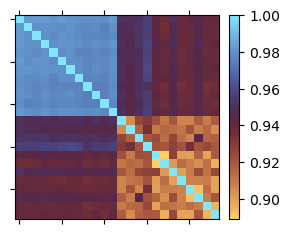

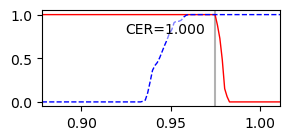

In [86]:
def plot_vector_covar(group_a, group_b, do_cal=False, vector_method='norm', distance_method='corr', smooth=None, plot_cdf=False, covar_out=None, cdf_out=None, fig_out=None, do_lines=False):
    group_a = sorted(group_a, key=lambda entry: entry['info']['serial'])
    group_b = sorted(group_b, key=lambda entry: entry['info']['serial'])
    all_traces = group_a + group_b

    if fig_out:
        covar_out = f'../paper/fig_covar_{fig_out}.pdf'
        cdf_out = f'../paper/fig_cdf_{fig_out}.pdf'
        
    d = np.zeros((len(all_traces), 12, roi_n))
    labels = []
    for i, entry in enumerate(all_traces):
        start, end = roi_map[entry['info']['chip']]
        labels.append(entry['info']['serial'])
        for j, (term, direction, channel) in enumerate(itertools.product(['open', 'short', 'load'], ['fwd', 'flip'], ['adc1', 'adc2'])):
            trace_data = np.array(entry['data'][f'{term}_{direction}'][channel])
            if do_cal:
                trace_data -= np.array(entry['data']['cal'][channel])
                
            if smooth is not None:
                t = np.linspace(0, 1, len(trace_data))
                spl = interpolate.make_smoothing_spline(t, trace_data, lam=smooth)
                trace_data = spl(t)
            
            d[i, j] = trace_data[start:end]
    
    # Normalize each curve such that its mean is at 0 and its min is at -1
    deltas = d[:,:,1:]
    deltas -= np.repeat(deltas.mean(axis=2)[:,:,np.newaxis], roi_n-1, axis=2)
    deltas /= np.repeat(deltas.max(axis=2)[:,:,np.newaxis], roi_n-1, axis=2)
    
    # Align all curves such that the trace starts where the trace crosses 0.5
    #roi_refined = round(np.mean(roi_n - 1 - np.argmax(deltas[:,::-1] > 0.5, axis=1))), roi_n
    #deltas = deltas[:,roi_refined[0]:roi_refined[1]]

    corr = np.zeros((12, len(all_traces), len(all_traces)))
    for i in range(12):
        if distance_method == 'corr':
            corr[i] = np.corrcoef(deltas[:,i,:])
        elif distance_method == 'max':
            for k, l in itertools.product(range(len(all_traces)), repeat=2):
                corr[i, k, l] = 1 - np.abs(deltas[k,i,:] - deltas[l,i,:]).max()
        else:
            raise ValueError(f'invalid distance_method {distance_method!r}')

    if vector_method == 'norm':
        corr = np.sqrt(np.mean(np.square(corr), axis=0))
    elif vector_method == 'min':
        corr = np.min(corr, axis=0)
    else:
        raise ValueError(f'invalid vector_method {vector_method!r}')
    
    within_class = corr[:len(group_a), :len(group_a)][np.triu_indices(len(group_a), 1)]
    cross_class = corr[len(group_a):, :len(group_a)].flatten()
    
    cdf = lambda x, mu, sigma: 1/2 * (1 + math.erf((x - mu) / (sigma * math.sqrt(2))))
    threshold = (np.mean(within_class) + np.mean(cross_class)) / 2
    #threshold = np.mean(within_class) -2*np.std(within_class)
    #threshold = (np.min(within_class) + np.max(cross_class)) / 2
    print(f'Baseline threshold set at {threshold:.6f}')
    
    for name, data in [('Within', within_class), ('Cross', cross_class)]:
        print(f'{name} class: {np.mean(data):.3g}±{np.std(data):.3g} min: {np.min(data):.3g} max: {np.max(data):.3g}')
    print(f'Baseline false negative probability: {cdf(threshold, np.mean(within_class), np.std(within_class)):.12f}')
    print(f'Baseline false positive probability: {1 - cdf(threshold, np.mean(cross_class), np.std(cross_class)):.12f}')
    
    #corr -= np.min(corr)
    #corr /= np.max(corr)
    
    #for i in range(len(corr[0])):
    #    corr[i, i] = math.nan
    
    fig, ax = plt.subplots(figsize=(3, 3))
    corr_ax = ax.matshow(corr, interpolation='none', cmap='managua')
    
    # https://stackoverflow.com/questions/18195758/set-matplotlib-colorbar-size-to-match-graph                   
    from mpl_toolkits.axes_grid1 import make_axes_locatable, axes_size
    divider = make_axes_locatable(ax)
    aspect = 20
    pad_fraction = 1
    width = axes_size.AxesY(ax, aspect=1./aspect)
    pad = axes_size.Fraction(pad_fraction, width)
    cax = divider.append_axes("right", size=width, pad=pad)
    plt.colorbar(corr_ax, cax=cax)

    #fig.colorbar(cax)
    #ax.set_xticks(list(range(len(labels))))
    #ax.set_xticklabels(labels, rotation=45, ha='left')
    #ax.set_yticks(list(range(len(labels))))
    #ax.set_yticklabels(labels)
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    if do_lines:
        ax.plot([-0.5, len(all_traces)-0.5], [len(group_a)-0.5, len(group_a)-0.5], '-', color='white', linewidth=1)
        ax.plot([len(group_a)-0.5, len(group_a)-0.5], [-0.5, len(all_traces)-0.5], '-', color='white', linewidth=1)
    fig.tight_layout()
    if covar_out:
        fig.savefig(covar_out)

    fig_c, ax_c = fig, ax
    if plot_cdf:
        fig, ax = plt.subplots(figsize=(3, 1.5))
        all_classes = [0] * len(group_a) + [1] * len(group_b)
        min_corr = corr.min()
        max_corr = corr.max()
        d_corr = max_corr - min_corr
        x = np.linspace(min_corr - 0.1*d_corr, max_corr + 0.1 * d_corr, 100)

        correct_in_group = lambda thr: np.mean(corr[np.triu_indices(len(group_a), 1)] >= thr)
        correct_out_group = lambda thr: np.mean(corr[:len(group_a), len(group_a):] < thr)

        cdf_in_group = [correct_in_group(val) for val in x]
        cdf_out_group = [correct_out_group(val) for val in x]

        for x1, x2, a, b, c, d in zip(x, x[1:], cdf_in_group, cdf_in_group[1:], cdf_out_group, cdf_out_group[1:]):
            if a >= c and b <= d:
                # lines cross
                if a == b == c == d:
                    eer = 1.0
                    eer_th = x2
                else:
                    eer_th = (c - a) / (b + c - a - d)
                    eer = eer_th * (d - c) + c
                    eer_th = eer_th*(x2 - x1) + x1
        print(f'EER: {eer} th: {eer_th}')
        #ax.axhline(eer)
        ax.axvline(eer_th, color='black', alpha=0.3, zorder=-2)
        offx, offy = 10, 0
        hora = 'left'
        if eer > 0.85:
            offy -= 15
        elif eer < 0.15:
            offy += 15
        if (eer_th - min_corr) / (max_corr - min_corr) > 0.7:
            offx = -offx
            hora = 'right'
        ax.annotate(f'CER={eer:.3f}', (eer_th, eer), (offx, offy), textcoords='offset pixels', verticalalignment='center', horizontalalignment=hora,
                   bbox={'boxstyle': 'square,pad=0.3', 'fc': '#ffffff80', 'ec': None, 'lw': 0})
        
        ax.plot(x, cdf_in_group, color='red', linewidth=1, linestyle='-')
        ax.plot(x, cdf_out_group, color='blue', linewidth=1, linestyle='--')
        ax.set_xlim((min(x), max(x)))
        fig.tight_layout()
        if cdf_out:
            fig.savefig(cdf_out)
        return fig_c, ax_c, fig, ax

    return fig_c, ax_c
    #fig.savefig('../paper/manip_pearson_corr.pdf')

#group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0003-0.4'][-5:]
#group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[1245]-0\.4', key)}.values())
#plot_vector_covar(group_a, group_b, distance_method='corr', smooth=None)

group_baseline = [value for value in data['M-SP-PITCH-V2-0010-0.3'] if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.3'][:12]
group_probed = [value for entries in data.values() for value in entries if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.3' and 'probe_points' in value['info']['mods']]
plot_vector_covar(group_baseline, group_probed, vector_method='norm', distance_method='corr', plot_cdf=True)

## Can we distinguish one specimen from other specimens with the same layout?

Baseline threshold set at 0.969534
Within class: 0.971±0.00177 min: 0.968 max: 0.974
Cross class: 0.968±0.00312 min: 0.963 max: 0.974
Baseline false negative probability: 0.239347408338
Baseline false positive probability: 0.344056606233
EER: 0.6333333333333333 th: 0.9696108071581744


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

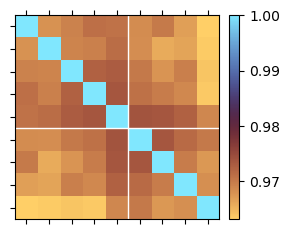

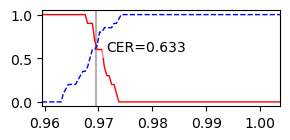

In [98]:
group_a = [val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and key == 'M-SP-PITCH-V2-0005-0.4'][-5:]
group_b = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[1234]-0\.4', key)}.values())
plot_vector_covar(group_a, group_b, plot_cdf=True, fig_out='distinguish_copies', do_lines=True)

## Can we distinguish mesh layout variants?

Compare measurements of five specimens of the base layout against measurements of each of the four alternate layouts.

Baseline threshold set at 0.035702
Within class: 0.318±0.0684 min: 0.221 max: 0.438
Cross class: -0.247±0.369 min: -1.01 max: 0.122
Baseline false negative probability: 0.000018117878
Baseline false positive probability: 0.221722565071
EER: 1.0 th: 0.2132482612886455


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

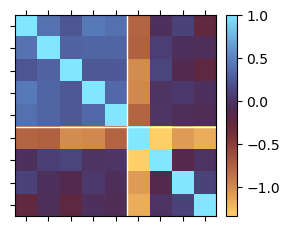

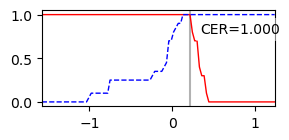

In [99]:
group_a = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and re.match(r'M-SP-PITCH-V2-000[12345]-0\.4', key)}.values())
group_b = list({val['info']['mesh_layout']: val for key, values in data.items() for val in values if val['info']['chip'] == 'pi3hdx12211' and 'ALT' in val['info']['mesh_layout']}.values())
plot_vector_covar(group_a, group_b, vector_method='min', distance_method='max', fig_out='distinguish_layouts', plot_cdf=True, do_lines=True)

#### Same measurement, but show TPD0604 data 

Baseline threshold set at 0.988280
Within class: 0.997±0.00035 min: 0.996 max: 0.997
Cross class: 0.98±0.0243 min: 0.935 max: 0.995
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.361190446191


(<Figure size 300x300 with 2 Axes>, <Axes: >)

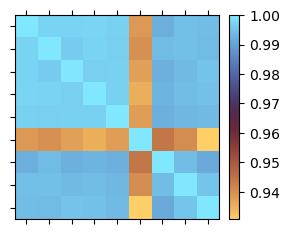

In [13]:
group_a = list({key: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and re.match(r'M-SP-PITCH-V2-000[12345]-0\.4', key)}.values())
group_b = list({val['info']['mesh_layout']: val for key, values in data.items() for val in values if val['info']['chip'] == 'tdp0604' and 'ALT' in val['info']['mesh_layout']}.values())
plot_vector_covar(group_a, group_b, do_cal=False)

Baseline threshold set at 0.872258
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.769±0.211 min: 0.488 max: 0.983
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.313260823987


(<Figure size 300x300 with 2 Axes>, <Axes: >)

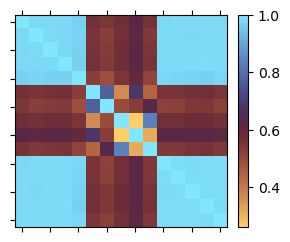

In [14]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.3])

Baseline threshold set at 0.701013
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.427±0.0442 min: 0.334 max: 0.489
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000271


(<Figure size 300x300 with 2 Axes>, <Axes: >)

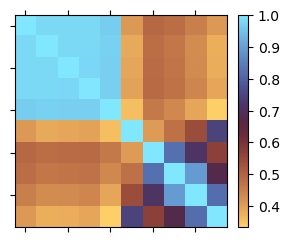

In [15]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.4])

Baseline threshold set at 0.648934
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.323±0.0409 min: 0.24 max: 0.374
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


(<Figure size 300x300 with 2 Axes>, <Axes: >)

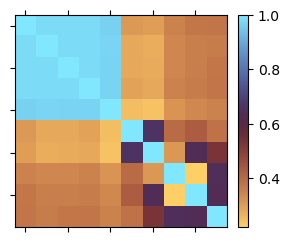

In [16]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 0.6])

Baseline threshold set at 0.584805
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.195±0.0352 min: 0.148 max: 0.265
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


(<Figure size 300x300 with 2 Axes>, <Axes: >)

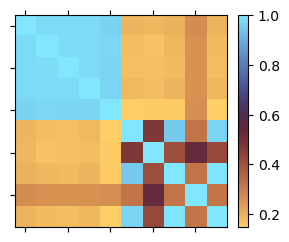

In [17]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_across_traces', 1.0])

Baseline threshold set at 0.912746
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.85±0.13 min: 0.663 max: 0.983
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.316362110922


(<Figure size 300x300 with 2 Axes>, <Axes: >)

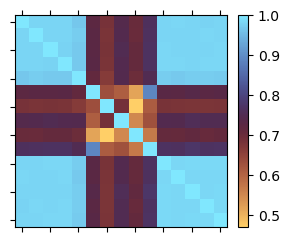

In [18]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.3])

Baseline threshold set at 0.760797
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.547±0.0224 min: 0.494 max: 0.573
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


(<Figure size 300x300 with 2 Axes>, <Axes: >)

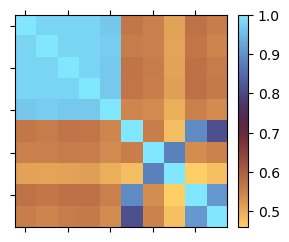

In [19]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.4])

Baseline threshold set at 0.677484
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.38±0.0891 min: 0.276 max: 0.548
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000422552353


(<Figure size 300x300 with 2 Axes>, <Axes: >)

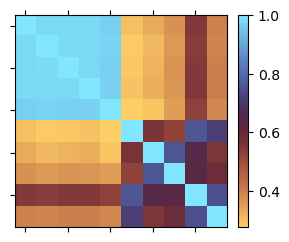

In [20]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 0.6])

Baseline threshold set at 0.625650
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.276±0.0863 min: 0.192 max: 0.467
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000025844305


(<Figure size 300x300 with 2 Axes>, <Axes: >)

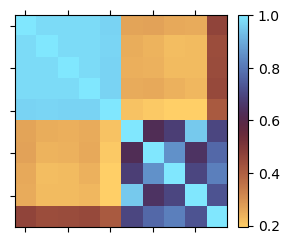

In [21]:
plot_vector_covar(mod_baseline[0.3], mod_modified['open', 1.0])

Baseline threshold set at 0.966650
Within class: 0.998±0.00182 min: 0.994 max: 0.999
Cross class: 0.936±0.0925 min: 0.73 max: 0.999
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.369113737192


(<Figure size 300x300 with 2 Axes>, <Axes: >)

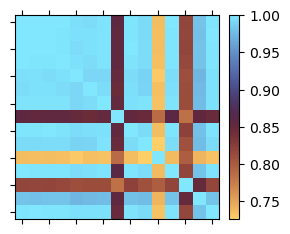

In [22]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.3], distance_method='corr', vector_method='norm', smooth=1e-5)

Baseline threshold set at 0.929626
Within class: 0.999±0.000803 max: 1
Cross class: 0.86±0.219 max: 1
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.375276121399


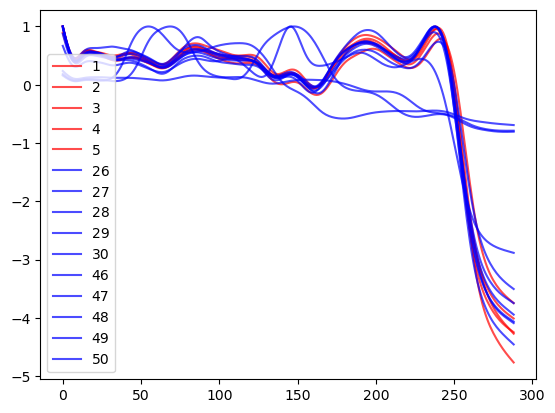

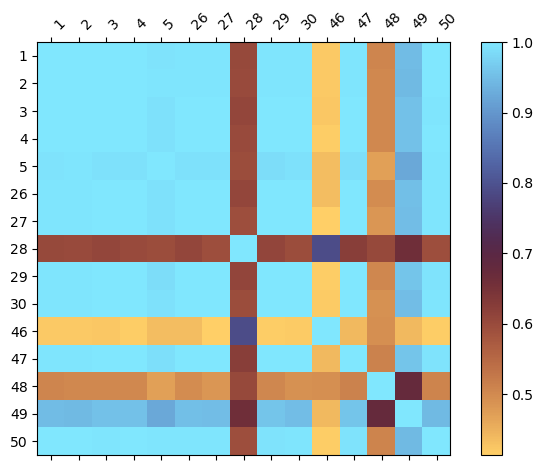

In [23]:
plot_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.3], select_trace='open_fwd', select_channel='adc1', smooth=1e-5)

Baseline threshold set at 0.802358
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.63±0.0632 min: 0.494 max: 0.704
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.003157026813


(<Figure size 300x300 with 2 Axes>, <Axes: >)

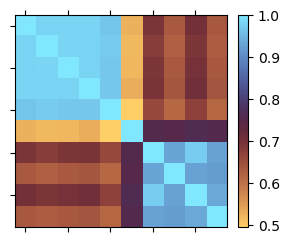

In [24]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.4])

Baseline threshold set at 0.658450
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.342±0.00931 min: 0.318 max: 0.353
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


(<Figure size 300x300 with 2 Axes>, <Axes: >)

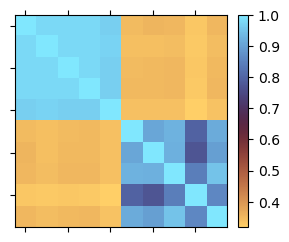

In [25]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 0.6])

Baseline threshold set at 0.621328
Within class: 0.975±0.00591 min: 0.966 max: 0.981
Cross class: 0.268±0.0242 min: 0.218 max: 0.313
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000


(<Figure size 300x300 with 2 Axes>, <Axes: >)

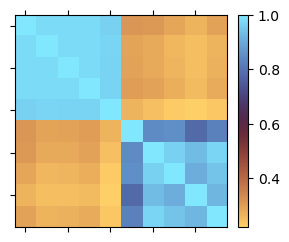

In [26]:
plot_vector_covar(mod_baseline[0.3], mod_modified['short_within_trace', 1.0])

Baseline threshold set at 0.956638
Within class: 0.998±0.000879 min: 0.996 max: 0.999
Cross class: 0.916±0.109 min: 0.703 max: 0.999
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.352476829164
Baseline threshold set at 0.814067
Within class: 0.991±0.0031 min: 0.984 max: 0.996
Cross class: 0.637±0.421 min: -0.132 max: 0.993
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.337040576195
Baseline threshold set at 0.897095
Within class: 0.891±0.0293 min: 0.828 max: 0.945
Cross class: 0.904±0.109 min: 0.739 max: 1.13
Baseline false negative probability: 0.586668632687
Baseline false positive probability: 0.523407808138
Baseline threshold set at -0.141600
Within class: 0.599±0.13 min: 0.252 max: 0.845
Cross class: -0.882±1.38 min: -3.02 max: 0.716
Baseline false negative probability: 0.000000006096
Baseline false positive probability: 0.295206150680
EER: 0.8270833333333333 th: 0.4730271886555954


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

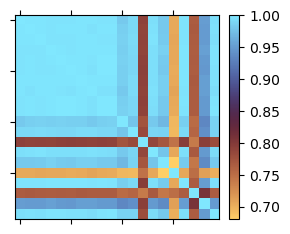

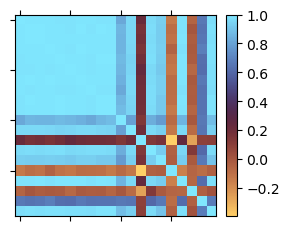

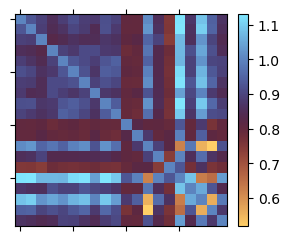

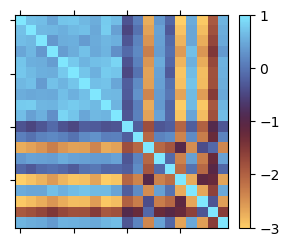

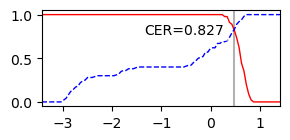

In [27]:
entries = [value for entry in data.values() for value in entry if value['info']['meta'] == 'interleaved-25-07-02-01-p0.3']
group_baseline = [value for value in entries if not value['info']['mods']]
group_modified = [value for value in entries if value['info']['mods']]

smooth = 1e-6
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='max', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='max', smooth=smooth, plot_cdf=True)

Baseline threshold set at 0.956638
Within class: 0.998±0.000879 min: 0.996 max: 0.999
Cross class: 0.916±0.109 min: 0.703 max: 0.999
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.352476829164
Baseline threshold set at 0.814067
Within class: 0.991±0.0031 min: 0.984 max: 0.996
Cross class: 0.637±0.421 min: -0.132 max: 0.993
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.337040576195
Baseline threshold set at 0.897095
Within class: 0.891±0.0293 min: 0.828 max: 0.945
Cross class: 0.904±0.109 min: 0.739 max: 1.13
Baseline false negative probability: 0.586668632687
Baseline false positive probability: 0.523407808138
Baseline threshold set at -0.141600
Within class: 0.599±0.13 min: 0.252 max: 0.845
Cross class: -0.882±1.38 min: -3.02 max: 0.716
Baseline false negative probability: 0.000000006096
Baseline false positive probability: 0.295206150680
EER: 0.8270833333333333 th: 0.4730271886555954


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

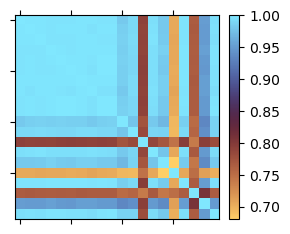

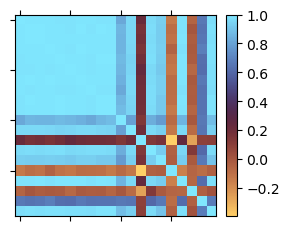

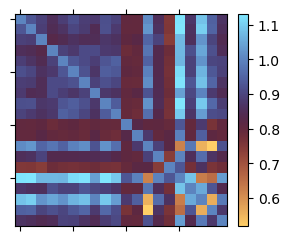

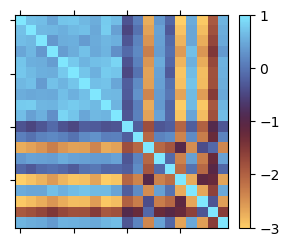

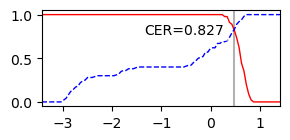

In [28]:
entries = [value for entry in data.values() for value in entry if value['info']['meta'] == 'interleaved-25-07-02-01-p0.3']
group_baseline = [value for value in entries if not value['info']['mods']]
group_modified = [value for value in entries if value['info']['mods']]

smooth = 1e-6
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='max', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='max', smooth=smooth, plot_cdf=True)


Baseline threshold set at 0.933157
Within class: 0.98±0.00188 min: 0.975 max: 0.983
Cross class: 0.886±0.106 min: 0.699 max: 0.982
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.328457736961
EER: 0.8788154897494305 th: 0.9765564861174376


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

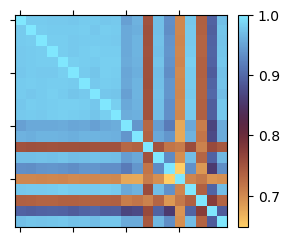

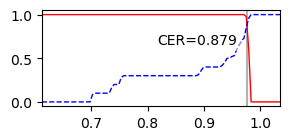

In [29]:
entries = [value for entry in data.values() for value in entry if value['info']['meta'] == 'interleaved-25-07-02-01-p0.3']
group_baseline = [value for value in entries if not value['info']['mods']]
group_modified = [value for value in entries if value['info']['mods']]

smooth = None
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True)

[['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace']]
Baseline threshold set at 0.960699
Within class: 0.995±0.00115 min: 0.991 max: 0.997
Cross class: 0.926±0.0893 min: 0.783 max: 0.996
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.349249068037
Baseline threshold set at 0.857937
Within class: 0.988±0.00299 min: 0.98 max: 0.993
Cross class: 0.728±0.353 min: -0.0684 max: 0.991
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.356244523468
Baseline threshold set at 0.768749
Within class: 0.86±0.0223 min: 0.793 max: 0.893
Cross class: 0.677±0.135 min: 0.397 max: 0.863
Baseline false negative probability: 0.000020032212
Baseline false positive probability: 0.248659653963
Baseline threshold set at 0.355298
Within class: 0.

(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

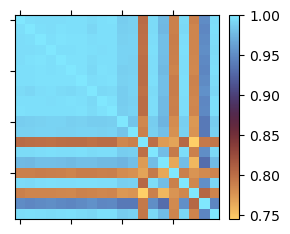

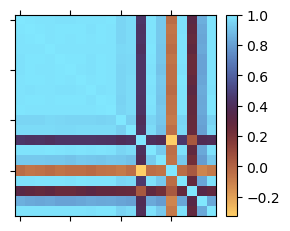

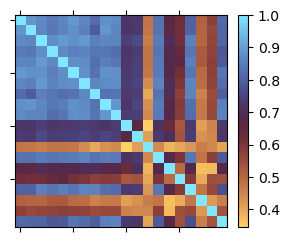

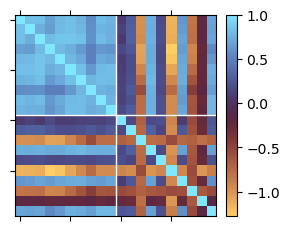

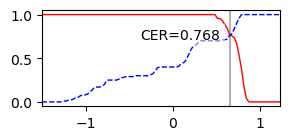

In [97]:
entries = [value for entry in data.values() for value in entry if value['info']['meta'] == 'interleaved-25-07-02-02-p0.3']
group_baseline = [value for value in entries if not value['info']['mods']]
group_modified = [value for value in entries if value['info']['mods']]
print([value['info']['mods'] for value in group_modified])

smooth = None
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='max', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='max', smooth=smooth, plot_cdf=True, fig_out='short_within_0.3_min_max', do_lines=True)

tdp0604 tdp0604
[['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace']]
Baseline threshold set at 0.960838
Within class: 0.996±0.000496 min: 0.995 max: 0.998
Cross class: 0.925±0.0896 min: 0.783 max: 0.996
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.345801726082
Baseline threshold set at 0.857032
Within class: 0.989±0.00226 min: 0.985 max: 0.994
Cross class: 0.725±0.358 min: -0.0808 max: 0.991
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.355768389397
Baseline threshold set at 0.773742
Within class: 0.903±0.00772 min: 0.879 max: 0.921
Cross class: 0.644±0.151 min: 0.373 max: 0.87
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.196044559641
Baseline threshold set at 0.4587

(<Figure size 300x300 with 2 Axes>, <Axes: >)

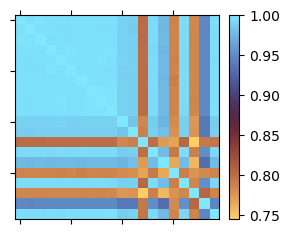

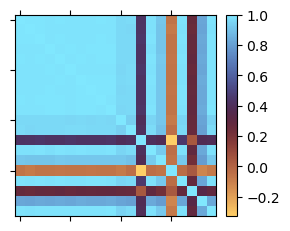

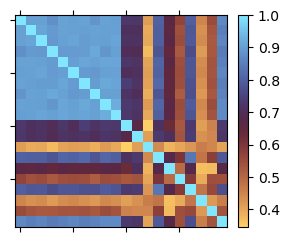

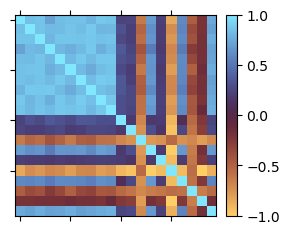

In [31]:
entries = [value for entry in data.values() for value in entry if value['info']['meta'] == 'interleaved-25-07-02-02-p0.3']
entries_repeat = [value for entry in data.values() for value in entry if value['info']['meta'] == 'baseline-repeat-25-07-02-01-p0.3']
print(entries[0]['info']['chip'], entries_repeat[0]['info']['chip'])
group_baseline = [value for value in entries_repeat if not value['info']['mods']][:10]
group_modified = [value for value in entries if value['info']['mods']]
print([value['info']['mods'] for value in group_modified])

smooth = None
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='corr', smooth=smooth)
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='max', smooth=smooth) 
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='max', smooth=smooth)

tdp0604 tdp0604
[['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace'], ['short_within_trace']]
Baseline threshold set at 0.960838
Within class: 0.996±0.000496 min: 0.995 max: 0.998
Cross class: 0.925±0.0896 min: 0.783 max: 0.996
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.345801726082
EER: 0.9174311926605505 th: 0.9948339629072368
Baseline threshold set at 0.458743
Within class: 0.834±0.0358 min: 0.717 max: 0.886
Cross class: 0.0832±0.499 min: -0.843 max: 0.775
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.225979489611
EER: 0.9659574468085106 th: 0.7515290358358554


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

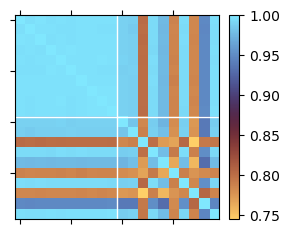

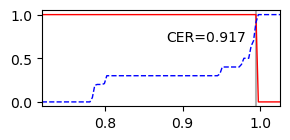

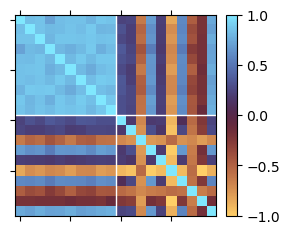

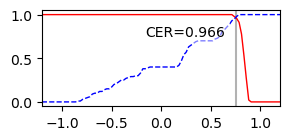

In [96]:
entries = [value for entry in data.values() for value in entry if value['info']['meta'] == 'interleaved-25-07-02-02-p0.3']
entries_repeat = [value for entry in data.values() for value in entry if value['info']['meta'] == 'baseline-repeat-25-07-02-01-p0.3']
print(entries[0]['info']['chip'], entries_repeat[0]['info']['chip'])
group_baseline = [value for value in entries_repeat if not value['info']['mods']][:10]
group_modified = [value for value in entries if value['info']['mods']]
print([value['info']['mods'] for value in group_modified])

smooth = None
plot_vector_covar(group_baseline, group_modified, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True, do_lines=True)
plot_vector_covar(group_baseline, group_modified, vector_method='min', distance_method='max', smooth=smooth, plot_cdf=True, do_lines=True)

pi3hdx12211
Baseline threshold set at 0.961379
Within class: 0.979±0.00182 min: 0.975 max: 0.983
Cross class: 0.944±0.00617 min: 0.934 max: 0.96
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.002633563073
EER: 1.0 th: 0.9747796526628734


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

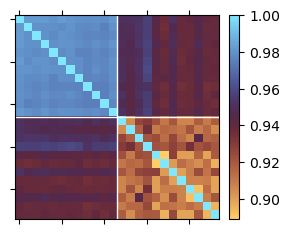

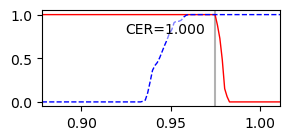

In [95]:
# probed with rigol PVP3150 probe, connected to running Rigol DS1054Z scope. probe grounded using ground clip to mesh specimen board ground area
# baseline also measured with ground clip connected to exclude grounding as the measured effect
group_baseline = [value for value in data['M-SP-PITCH-V2-0010-0.3'] if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.3'][:12]
group_probed = [value for entries in data.values() for value in entries if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.3' and 'probe_points' in value['info']['mods']]
print(group_baseline[0]['info']['chip'])

smooth = None
plot_vector_covar(group_baseline, group_probed, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True, fig_out='probe_0.3', do_lines=True)

Baseline threshold set at 0.951092
Within class: 0.972±0.00261 min: 0.965 max: 0.976
Cross class: 0.93±0.00368 min: 0.919 max: 0.937
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000009101
EER: 1.0 th: 0.9640827677501544


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

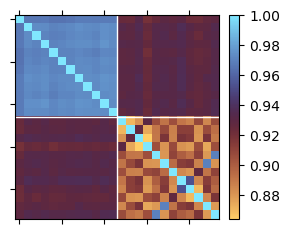

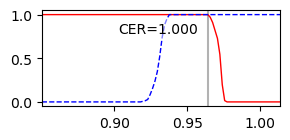

In [94]:
group_baseline = [value for value in data['M-SP-PITCH-V2-0010-0.4'] if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.4'][:12]
group_probed = [value for entries in data.values() for value in entries if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.4' and 'probe_points' in value['info']['mods']]

smooth = None
plot_vector_covar(group_baseline, group_probed, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True, fig_out='probe_0.4', do_lines=True)

Baseline threshold set at 0.953939
Within class: 0.984±0.00094 min: 0.982 max: 0.986
Cross class: 0.924±0.0132 min: 0.89 max: 0.948
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.011374090429
EER: 1.0 th: 0.9811027642073021


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

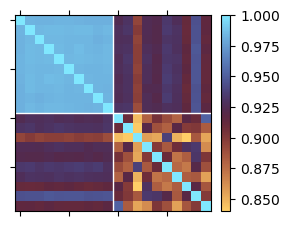

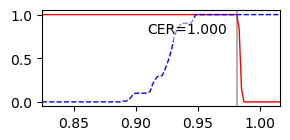

In [93]:
group_baseline = [value for value in data['M-SP-PITCH-V2-0004-0.3'] if value['info']['meta'] == 'touch-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]
group_touch = [value for value in data['M-SP-PITCH-V2-0005-0.3'] if value['info']['meta'] == 'touch-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]

smooth = None
plot_vector_covar(group_baseline, group_touch, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True, fig_out='touch_mesh', do_lines=True)

Baseline threshold set at 0.983298
Within class: 0.984±0.000888 min: 0.982 max: 0.986
Cross class: 0.982±0.000887 min: 0.981 max: 0.985
Baseline false negative probability: 0.144158897703
Baseline false positive probability: 0.143935028357
EER: 0.8323809523809523 th: 0.9831607423686642


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

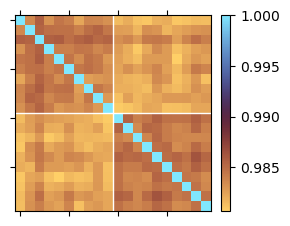

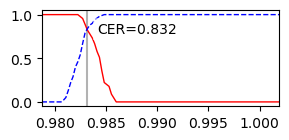

In [92]:
group_baseline = [value for value in data['M-SP-PITCH-V2-0004-0.3'] if value['info']['meta'] == 'touch-ground-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]
group_touch = [value for value in data['M-SP-PITCH-V2-0005-0.3'] if value['info']['meta'] == 'touch-ground-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]

smooth = None
plot_vector_covar(group_baseline, group_touch, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True, fig_out='touch_ground', do_lines=True)

Baseline threshold set at 0.968515
Within class: 0.984±0.00094 min: 0.982 max: 0.986
Cross class: 0.953±0.0306 min: 0.89 max: 0.985
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.306841485128
EER: 0.862061155152888 th: 0.9828214430266746


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

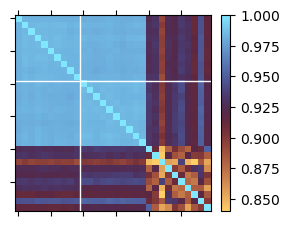

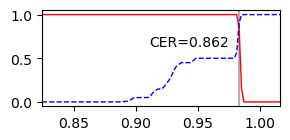

In [91]:
# touch group: touched with one or more fingers directly to the mesh surface
# ground group: ground plane of mesh specimen board firmly touched, but mesh not touched directly
group_baseline = [value for value in data['M-SP-PITCH-V2-0004-0.3'] if value['info']['meta'] == 'touch-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]
group_touch_ground = [value for value in data['M-SP-PITCH-V2-0005-0.3'] if value['info']['meta'] == 'touch-ground-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]
group_touch = [value for value in data['M-SP-PITCH-V2-0005-0.3'] if value['info']['meta'] == 'touch-interleave-touch-serial-5-25-07-02-01-p0.3'][:10]

smooth = None
plot_vector_covar(group_baseline, group_touch_ground + group_touch, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True, fig_out='touch_combined', do_lines=True)

Baseline threshold set at 0.973977
Within class: 0.983±0.000806 min: 0.981 max: 0.984
Cross class: 0.965±0.0058 min: 0.946 max: 0.972
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.069349012210
EER: 1.0 th: 0.9805802709390348


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

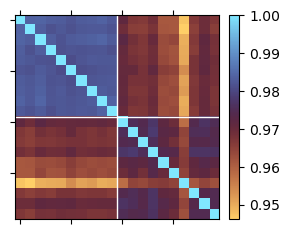

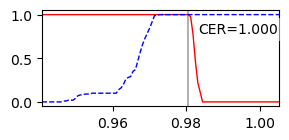

In [90]:
# Mesh 5 heated up to 60 ~ 70 Celsius
group_baseline = [value for value in data['M-SP-PITCH-V2-0004-0.3'] if value['info']['meta'] == 'hot-mesh-hot-serial-5-25-07-02-01-p0.3'][:10]
group_touch = [value for value in data['M-SP-PITCH-V2-0005-0.3'] if value['info']['meta'] == 'hot-mesh-hot-serial-5-25-07-02-01-p0.3'][:10]

smooth = None
plot_vector_covar(group_baseline, group_touch, vector_method='norm', distance_method='corr', smooth=smooth, plot_cdf=True, fig_out='hot_mesh', do_lines=True)

2025-07-02T14:12:06.264Z
2025-07-02T16:44:21.617Z
Baseline threshold set at 0.979363
Within class: 0.979±0.00174 min: 0.975 max: 0.983
Cross class: 0.98±0.00134 min: 0.976 max: 0.983
Baseline false negative probability: 0.599033216599
Baseline false positive probability: 0.627495097441
EER: 0.3970149253731343 th: 0.9795569289147479
Baseline threshold set at 0.404340
Within class: 0.418±0.0836 min: 0.208 max: 0.539
Cross class: 0.39±0.0899 min: 0.105 max: 0.539
Baseline false negative probability: 0.433140871718
Baseline false positive probability: 0.437791410191
EER: 0.5764705882352941 th: 0.42234734134839336


(<Figure size 300x300 with 2 Axes>,
 <Axes: >,
 <Figure size 300x150 with 1 Axes>,
 <Axes: >)

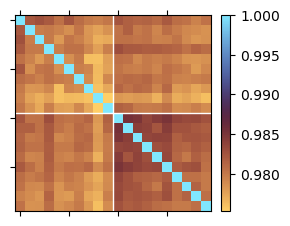

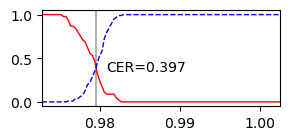

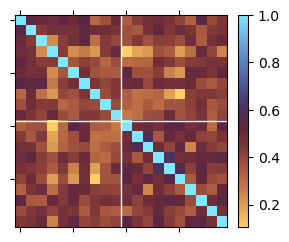

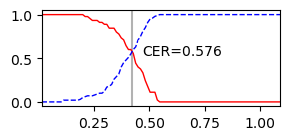

In [100]:
# Compare measurements taken several hours apart, with the board running and measuring a mesh the whole time in between.

group_a = [value for value in data['M-SP-PITCH-V2-0010-0.3'] if value['info']['meta'] == 'probe-interleave-25-07-02-01-p0.3'][:10]
group_b = [value for entry in data.values() for value in entry if value['info']['meta'] == 'baseline-repeat-25-07-02-02-p0.3']
print(group_a[-1]['info']['timestamp'])
print(group_b[-1]['info']['timestamp'])
plot_vector_covar(group_a, group_b, vector_method='norm', distance_method='corr', plot_cdf=True, fig_out='time_drift', do_lines=True)
plot_vector_covar(group_a, group_b, vector_method='min', distance_method='max', plot_cdf=True, fig_out='time_drift_minmax', do_lines=True)

short_across_traces 0.3
10 2025-07-07T11:12:08.214Z
10 2025-07-07T11:09:39.478Z
Baseline threshold set at -1.782883
Within class: 0.434±0.0686 min: 0.312 max: 0.558
Cross class: -4±0.303 min: -4.75 max: -3.5
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000000000000
EER: 1.0 th: 0.2915482296934595
short_across_traces 0.4
10 2025-07-07T11:24:19.057Z
10 2025-07-07T11:21:55.882Z
Baseline threshold set at -1.170734
Within class: 0.263±0.0995 min: -0.0456 max: 0.438
Cross class: -2.6±0.907 min: -4.33 max: -1.5
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.057067296898
EER: 1.0 th: -0.08129093490444816
open 0.3
10 2025-07-07T11:12:08.214Z
10 2025-07-07T11:14:58.826Z
Baseline threshold set at -1.115170
Within class: 0.434±0.0686 min: 0.312 max: 0.558
Cross class: -2.66±0.435 min: -3.46 max: -1.73
Baseline false negative probability: 0.000000000000
Baseline false positive probability: 0.000186851636
EER: 

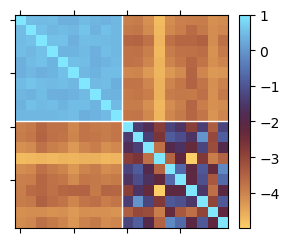

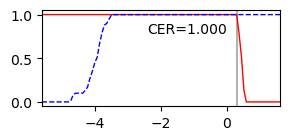

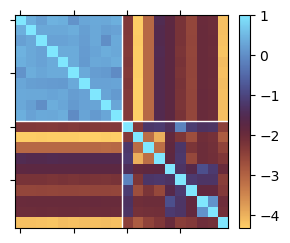

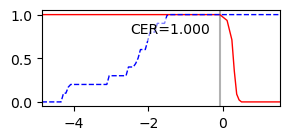

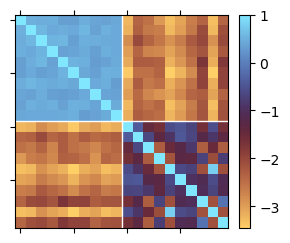

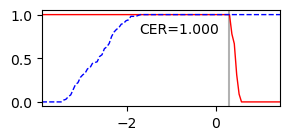

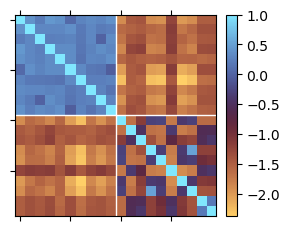

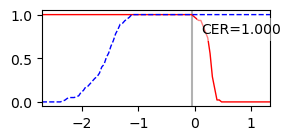

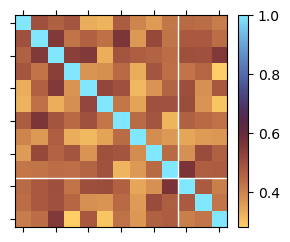

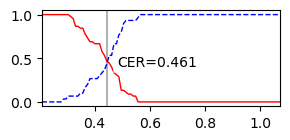

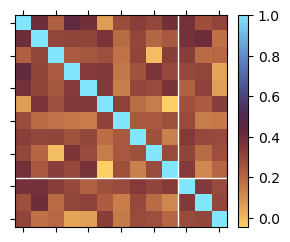

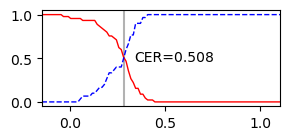

In [88]:
# Can we distinguish baseline versus shorted A/B traces?
for mod in ['short_across_traces', 'open', 'probe_points']:
    for pitch in ['0.3', '0.4']:
        print(f'{mod} {pitch}')
        group_a = [value for value in data_runs[f'simple-attack-25-07-07-01-p{pitch}'] if not value['info']['mods']]
        group_b = [value for value in data_runs[f'simple-attack-25-07-07-01-p{pitch}'] if mod in value['info']['mods']]
        if not group_a or not group_b:
            print('(skip)')
            continue
        
        print(len(group_a), group_a[-1]['info']['timestamp'])
        print(len(group_b), group_b[-1]['info']['timestamp'])
        plot_vector_covar(group_a, group_b, vector_method='min', distance_method='max', plot_cdf=True, fig_out=f'{mod}_p{pitch}', do_lines=True)